In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [48]:
df=pd.read_csv("HR_comma_sep.csv")

In [49]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [50]:
left=df[df.left==1]

In [51]:
left.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [52]:
df.groupby('left').mean(numeric_only=True)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years
left,,,,,,,
0,0.666810,0.715473,3.786664,199.060203,3.380032,0.175009,0.026251
1,0.440098,0.718113,3.855503,207.419210,3.876505,0.047326,0.005321


In [53]:
#Satisfaction level, hourspromotion

<Axes: xlabel='salary'>

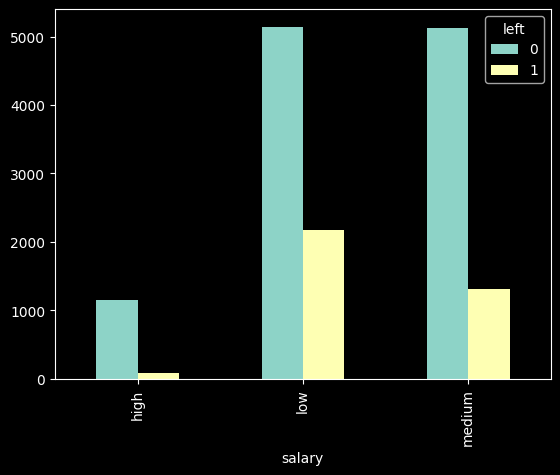

In [54]:
pd.crosstab(df.salary,df.left).plot(kind='bar')

In [55]:
#Salary

In [56]:
subdf=df[['salary','promotion_last_5years','satisfaction_level','average_montly_hours']]

In [57]:
subdf

,salary,promotion_last_5years,satisfaction_level,average_montly_hours
0,low,0,0.38,157
1,medium,0,0.80,262
2,medium,0,0.11,272
3,low,0,0.72,223
4,low,0,0.37,159
...,...,...,...,...
14994,low,0,0.40,151
14995,low,0,0.37,160
14996,low,0,0.37,143
14997,low,0,0.11,280


In [58]:
p=pd.get_dummies(df.salary,prefix='salary')

In [59]:
subdf=pd.concat([subdf,p],axis="columns")

In [60]:
subdf

,salary,promotion_last_5years,satisfaction_level,average_montly_hours,salary_high,salary_low,salary_medium
0,low,0,0.38,157,False,True,False
1,medium,0,0.80,262,False,False,True
2,medium,0,0.11,272,False,False,True
3,low,0,0.72,223,False,True,False
4,low,0,0.37,159,False,True,False
...,...,...,...,...,...,...,...
14994,low,0,0.40,151,False,True,False
14995,low,0,0.37,160,False,True,False
14996,low,0,0.37,143,False,True,False
14997,low,0,0.11,280,False,True,False


In [61]:
subdf.drop('salary',axis='columns',inplace=True)

In [62]:
subdf

,promotion_last_5years,satisfaction_level,average_montly_hours,salary_high,salary_low,salary_medium
0,0,0.38,157,False,True,False
1,0,0.80,262,False,False,True
2,0,0.11,272,False,False,True
3,0,0.72,223,False,True,False
4,0,0.37,159,False,True,False
...,...,...,...,...,...,...
14994,0,0.40,151,False,True,False
14995,0,0.37,160,False,True,False
14996,0,0.37,143,False,True,False
14997,0,0.11,280,False,True,False


In [63]:
from sklearn import linear_model

In [64]:
model=linear_model.LogisticRegression()

In [65]:
x=subdf

In [66]:
y=df.left

In [67]:
from sklearn.model_selection import train_test_split

In [68]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3)

In [69]:
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [70]:
model.predict(x_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(4500,))

In [71]:
y_test

3397     0
13345    0
10917    0
12991    0
12186    1
        ..
13419    0
10763    0
4776     0
3413     0
10337    0
Name: left, Length: 4500, dtype: int64

In [72]:
model.score(x_test,y_test)

0.774

In [73]:
import joblib

In [91]:
joblib.dump(model,'modelj')

['modelj']

In [94]:
m=joblib.load('modelj')

In [96]:
m.score(x_test,y_test)

0.774